## Mapillary API: Initial Access and Retrieval Test

### Completed
- Registered a Mapillary application and configured an access token.
- Successfully queried image metadata within a small bounding box in Back Bay, Boston.
- Retrieved image IDs, capture timestamps, and geographic coordinates.
- Tested a capture-date filter for images taken before January 1, 2023.
- Retrieved five image records satisfying that filter.
- Successfully displayed a preview of an image captured on December 7, 2019.

### Initial Observations
- The test queries returned images captured in 2015, 2017, 2019, and 2023.
- A larger-area query failed with a request to reduce the amount of data; a smaller-area query succeeded.

### Limitations and Next Steps
- These results are a small sample, not a complete image inventory.
- The earliest and latest available capture dates have not been established.
- The pre-2023 filter was used for testing; final image-date eligibility requires team agreement.
- Next: collect paginated metadata, summarize capture-year availability, and assess coverage against road segments.

## 1. Load the access token
Enter the Mapillary access token using a hidden input prompt.
The token is not written directly into the code.

In [7]:
from getpass import getpass

MAPILLARY_TOKEN = getpass("Paste your Mapillary Access Token: ").strip()
print("Token loaded:", bool(MAPILLARY_TOKEN))

Token loaded: True


## 2. Test a small-area image query
Query a small bounding box in Back Bay and retrieve one image ID
to verify API access.

In [11]:
import requests
import pandas as pd

response = requests.get(
    "https://graph.mapillary.com/images",
    headers={"Authorization": f"OAuth {MAPILLARY_TOKEN}"},
    params={
        "fields": "id",
        # Bounding box: west, south, east, north.
        "bbox": "-71.0805,42.3500,-71.0795,42.3510",
        "limit": 1,
    },
    timeout=30,
)

print("HTTP status:", response.status_code)

result = response.json()

if response.ok and "data" in result:
    images_test = pd.json_normalize(result["data"])

    print("Images returned:", len(images_test))
    display(images_test)
else:
    error = result.get("error", {})
    print("Error code:", error.get("code"))
    print("Error type:", error.get("type"))

HTTP status: 200
Images returned: 1


,id
0,149213781588332


## 3. Inspect image metadata
Retrieve the image capture date and coordinates.
Check whether the image was captured before January 1, 2023.

In [12]:
# Retrieve metadata for the image returned by the test query.
image_id = str(images_test.iloc[0]["id"])

detail_response = requests.get(
    f"https://graph.mapillary.com/{image_id}",
    headers={"Authorization": f"OAuth {MAPILLARY_TOKEN}"},
    params={"fields": "id,captured_at,geometry"},
    timeout=30,
)

print("HTTP status:", detail_response.status_code)
image_detail = detail_response.json()

if detail_response.ok and "captured_at" in image_detail:
    captured_date = pd.to_datetime(
        image_detail["captured_at"], unit="ms", utc=True
    )

    print("Image ID:", image_detail["id"])
    print("Captured date:", captured_date)
    print("Coordinates:", image_detail.get("geometry"))
    print("Captured before 2023:", captured_date < pd.Timestamp("2023-01-01", tz="UTC"))
else:
    error = image_detail.get("error", {})
    message = str(error.get("message", "No error message returned."))
    print("Error message:", message.replace(MAPILLARY_TOKEN, "[REDACTED]"))

HTTP status: 200
Image ID: 149213781588332
Captured date: 2023-03-23 14:28:00.600000+00:00
Coordinates: {'type': 'Point', 'coordinates': [-71.0798861, 42.350321]}
Captured before 2023: False


## 4. Test a capture-date filter
Retrieve up to five images captured before January 1, 2023.
This is a test filter; final date eligibility requires team agreement.

In [13]:
# Query a small area for images captured before 2023.
response = requests.get(
    "https://graph.mapillary.com/images",
    headers={"Authorization": f"OAuth {MAPILLARY_TOKEN}"},
    params={
        "fields": "id,captured_at,geometry",
        # Bounding box: west, south, east, north.
        "bbox": "-71.0805,42.3500,-71.0795,42.3510",
        "end_captured_at": "2023-01-01T00:00:00Z",
        "limit": 5,
    },
    timeout=30,
)

print("HTTP status:", response.status_code)
result = response.json()

if response.ok and "data" in result:
    images_pre2023 = pd.json_normalize(result["data"])
    print("Images returned:", len(images_pre2023))

    if not images_pre2023.empty:
        images_pre2023["captured_date"] = pd.to_datetime(
            images_pre2023["captured_at"], unit="ms", utc=True
        )

        # Verify the strict date cutoff locally.
        images_pre2023 = images_pre2023.loc[
            images_pre2023["captured_date"]
            < pd.Timestamp("2023-01-01", tz="UTC")
        ].copy()

        display(images_pre2023)
    else:
        print("No images returned for this area and date filter.")
else:
    error = result.get("error", {})
    message = str(error.get("message", "No error message returned."))
    print("Error message:", message.replace(MAPILLARY_TOKEN, "[REDACTED]"))

HTTP status: 200
Images returned: 5


,id,captured_at,geometry.type,geometry.coordinates,captured_date
0,1895595393932577,1424536159000,Point,"[-71.080256, 42.350194]",2015-02-21 16:29:19+00:00
1,178987897446385,1575742331137,Point,"[-71.080394, 42.350175]",2019-12-07 18:12:11.137000+00:00
2,206984607900132,1507150224096,Point,"[-71.080411495707, 42.35018138312]",2017-10-04 20:50:24.096000+00:00
3,298583888394353,1507213814200,Point,"[-71.080271388095, 42.350175767944]",2017-10-05 14:30:14.200000+00:00
4,3867538943353649,1575742328137,Point,"[-71.080333, 42.350175]",2019-12-07 18:12:08.137000+00:00


## 5. Display an image preview
Display the most recently captured image within the five-record sample.
This does not establish the latest available image in the area.

HTTP status: 200
Image ID: 178987897446385
Captured date: 2019-12-07 18:12:11.137000+00:00


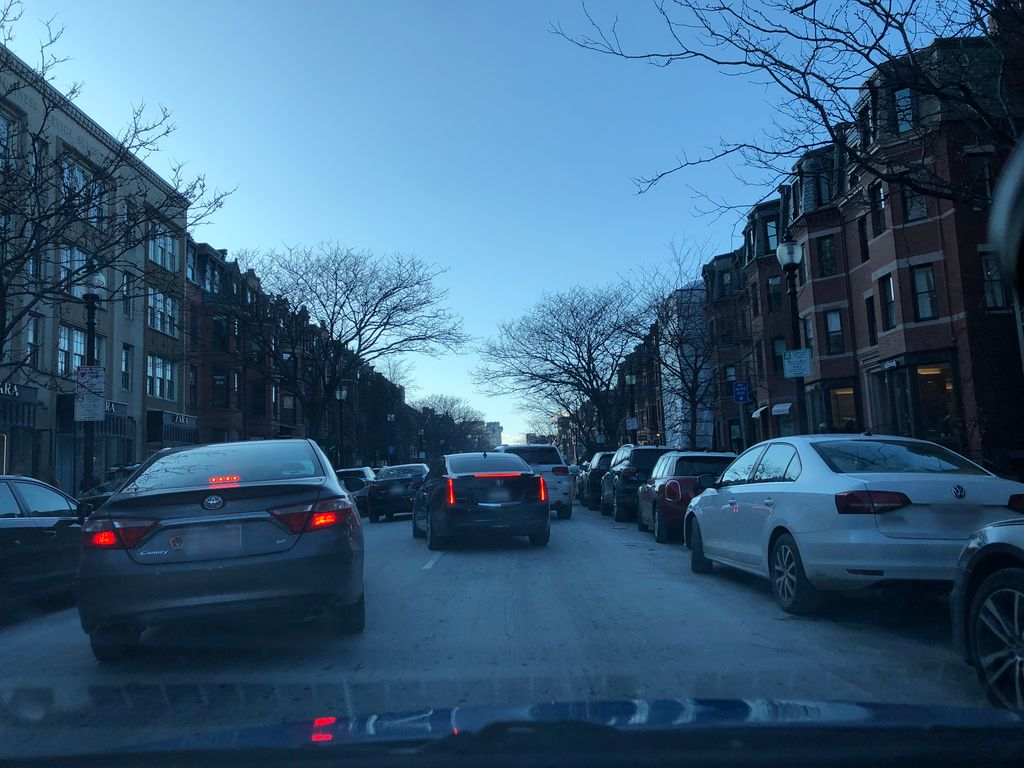

In [14]:
from IPython.display import Image, display

# Select the most recent image in the current sample.
selected = images_pre2023.sort_values(
    "captured_date", ascending=False
).iloc[0]

image_id = str(selected["id"])

# Request a preview URL for the selected image.
preview_response = requests.get(
    f"https://graph.mapillary.com/{image_id}",
    headers={"Authorization": f"OAuth {MAPILLARY_TOKEN}"},
    params={"fields": "id,thumb_1024_url"},
    timeout=30,
)

print("HTTP status:", preview_response.status_code)
preview = preview_response.json()

if preview_response.ok and preview.get("thumb_1024_url"):
    print("Image ID:", image_id)
    print("Captured date:", selected["captured_date"])

    # Fetch the preview without forwarding the API authorization header.
    photo_response = requests.get(
        preview["thumb_1024_url"], timeout=30
    )

    if photo_response.ok:
        display(Image(data=photo_response.content))
    else:
        print("Image download status:", photo_response.status_code)
else:
    error = preview.get("error", {})
    message = str(error.get("message", "No preview URL returned."))
    print("Error message:", message.replace(MAPILLARY_TOKEN, "[REDACTED]"))